In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_list = glob.glob(
    "/kaggle/input/**/synthetic_breast_cancer_svm_dataset.csv",
    recursive=True
)

if not file_list:
    raise FileNotFoundError(
        "CSV nahi mili. Kaggle Notebook mein Add Input se dataset add karo."
    )

df = pd.read_csv(file_list[0])

print("Dataset loaded successfully!")
print("File path:", file_list[0])
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File path: /kaggle/input/datasets/mudasir123312/synthetic-breast-cancer-svm-data/synthetic_breast_cancer_svm_dataset.csv
Dataset shape: (569, 32)


,sample_id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,diagnosis
0,1,-5.676738,1.641429,1.662931,-1.323951,1.324644,4.637255,0.056511,-3.210208,3.292247,...,-2.010217,2.898742,-4.965189,-1.361414,-0.715238,-7.835811,-4.530456,3.910286,-1.230877,Malignant
1,2,0.610475,1.100393,-0.974453,0.342099,0.956430,-3.149597,3.377768,0.249501,-1.013034,...,0.349364,-0.544965,-1.550994,-0.169862,-0.973491,0.931780,-2.325168,-0.416833,0.712912,Benign
2,3,-6.447604,-1.324846,0.757177,-0.032481,-1.082482,-2.084313,0.571141,-1.953505,-0.276635,...,-0.321753,-1.256203,-1.387800,5.825312,-1.294352,-9.097784,-0.792090,1.534549,1.049971,Benign
3,4,0.619196,0.445948,1.335113,-0.172626,-4.475227,-7.319651,0.966917,2.898533,2.061654,...,0.558232,1.698074,0.219788,2.102817,-1.641103,14.009534,-4.416207,-4.917367,-4.613678,Benign
4,5,2.330032,0.231541,0.790686,0.832401,-1.585813,-4.079743,0.524793,0.452076,2.027810,...,-0.187074,1.919293,-3.272642,-0.021927,0.251813,6.108438,-4.612093,-0.983216,-1.923483,Benign


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Column names:
['sample_id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'diagnosis']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   sample_id                569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_me

In [4]:
print("Class counts:")
print(df["diagnosis"].value_counts())

print("\nClass percentages:")
print(
    (df["diagnosis"].value_counts(normalize=True) * 100).round(2)
)

Class counts:
diagnosis
Benign       360
Malignant    209
Name: count, dtype: int64

Class percentages:
diagnosis
Benign       63.27
Malignant    36.73
Name: proportion, dtype: float64


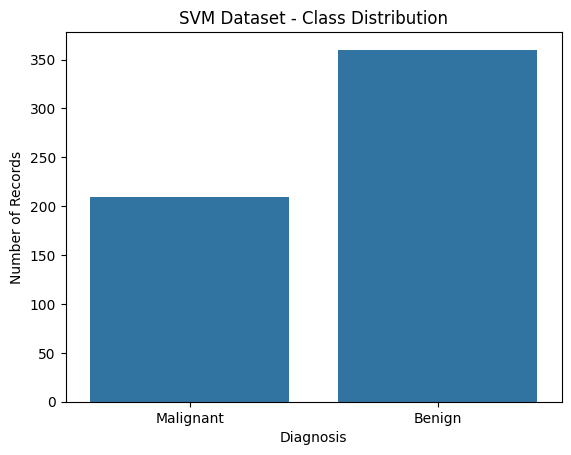

In [5]:
sns.countplot(data=df, x="diagnosis")

plt.title("SVM Dataset - Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.show()

In [6]:
X = df.drop(columns=["diagnosis", "sample_id"])
y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (569, 30)
Target shape: (569,)

Feature columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 455
Testing records: 114

Training class distribution:
diagnosis
Benign       288
Malignant    167
Name: count, dtype: int64

Testing class distribution:
diagnosis
Benign       72
Malignant    42
Name: count, dtype: int64


In [8]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_model.fit(X_train, y_train)

print("SVM model training completed!")

SVM model training completed!


In [9]:
y_pred = svm_model.predict(X_test)

results = pd.DataFrame({
    "Actual Diagnosis": y_test,
    "Predicted Diagnosis": y_pred
})

display(results.head(10))

,Actual Diagnosis,Predicted Diagnosis
118,Benign,Benign
402,Malignant,Malignant
324,Benign,Benign
201,Malignant,Malignant
298,Benign,Benign
247,Benign,Benign
114,Malignant,Malignant
47,Benign,Benign
413,Benign,Benign
485,Benign,Benign


In [10]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="Malignant"
)
recall = recall_score(
    y_test, y_pred, pos_label="Malignant"
)
f1 = f1_score(
    y_test, y_pred, pos_label="Malignant"
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Malignant Precision: {precision * 100:.2f}%")
print(f"Malignant Recall: {recall * 100:.2f}%")
print(f"Malignant F1-score: {f1 * 100:.2f}%")

print("\nComplete Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

Test Accuracy: 95.61%
Malignant Precision: 97.44%
Malignant Recall: 90.48%
Malignant F1-score: 93.83%

Complete Classification Report:
              precision    recall  f1-score   support

      Benign     0.9467    0.9861    0.9660        72
   Malignant     0.9744    0.9048    0.9383        42

    accuracy                         0.9561       114
   macro avg     0.9605    0.9454    0.9521       114
weighted avg     0.9569    0.9561    0.9558       114



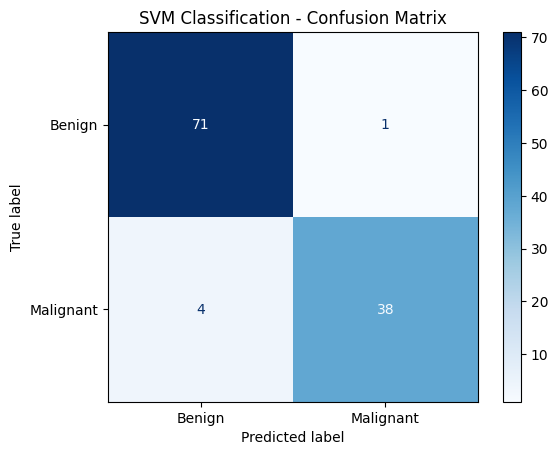

Confusion Matrix:
[[71  1]
 [ 4 38]]


In [11]:
labels = ["Benign", "Malignant"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title("SVM Classification - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [12]:
print("=" * 45)
print("BREAST CANCER SVM CLASSIFICATION")
print("=" * 45)

print("Total records:", len(df))
print("Total input features:", X.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Classes:", y.nunique())
print(f"Test Accuracy: {accuracy * 100:.2f}%")

if accuracy >= 0.95:
    print("Test accuracy is 95% or higher.")
else:
    print("Test accuracy is below 95%.")

print("\nEvaluation completed successfully.")

BREAST CANCER SVM CLASSIFICATION
Total records: 569
Total input features: 30
Training records: 455
Testing records: 114
Classes: 2
Test Accuracy: 95.61%
Test accuracy is 95% or higher.

Evaluation completed successfully.
